In [18]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('C:\Internal_Tank_Registration\Point-Cloud-Registration\source')

import pickle
import os
import gc
from copy import deepcopy
import pandas as pd
import numpy as np
from glob import glob
from pathlib import Path
import matplotlib.pyplot as plt
from multiprocessing import Pool
import open3d as o3d
import time

from cylinder_alignment.bundle_station import BundleStation
from cylinder_extraction.station import Station
from cylinder_alignment.station_alignment import StationAlignment
from cylinder_alignment.utils import extract_target_cylinder
from utils.write_output import write_array2txt
from utils.math_methods import calc_overlap_curve
from registration.utils import pairwise_registration, combine_point_cloud

import plotly.express as px

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


5 mins
5


In [4]:
scan_field_names = [
    ('Loose Registration',8),
]
field, pack_num = scan_field_names[0]
time_begin = time.time()
print('===========================')
print(field)
data_dir = Path(f'C:/Users/Administrator/Desktop/PointCloudRegistration/Data/External/Tank 43_Loose Registration/{field}')
# # READ EXTRACTED CYLINDERS DATA
# bundle = BundleStation(data_dir=data_dir)
# summary_df = bundle.read_extracted_cylinder_data(file_types=['e57'])
# # ############################
# # px.scatter(
# #     summary_df[summary_df.radius < 50], y='radius', x='station', 
# #     color='station', hover_data=summary_df.columns
# # )
# # PAIRWISE STATION ALIGNMENT
# bundle.align_pairwise_station()
# time_pairwise = time.time()
# # Save
# bundle.remove_points()
# with open(os.path.join(data_dir, 'rough_alignment.pkl'), 'wb') as f:
#     pickle.dump(bundle, f)
# # load
# with open(os.path.join(data_dir, 'rough_alignment.pkl'), 'rb') as f:
#     bundle = pickle.load(f)
# # uncertain stations
# uncertain_stations = bundle.find_uncertain_stations()
# if len(uncertain_stations) > 0:
#     print('uncertain stations')
#     print(uncertain_stations)
#     raise ValueError('Uncertain stations exist')
# # bundle.handle_uncertain(
# #     neighbor_info={
# #         '009': '008',
# #         '016': '015',
# #         '018': '017'
# #     }
# # )
# # bring all stations to a global coordinate
# bundle.align_all_stations_by_axis()
# # CLUSTER TANKS
# bundle.cluster_cylinder()
# time_cluster = time.time()
# # save
# bundle.remove_points()
# with open(os.path.join(data_dir, 'globalization_center_phase_1.pkl'), 'wb') as f:
#     pickle.dump(bundle, f)
# with open(os.path.join(data_dir, 'globalization_center_phase_1.pkl'), 'rb') as f:
#     bundle = pickle.load(f)
# # VISUAL INSPECTION
# fig = bundle.draw_cross_section()
# fig.show()      

Loose Registration


In [5]:
# READ EXTRACTED CYLINDERS DATA
bundle = BundleStation(data_dir=data_dir)
summary_df = bundle.read_extracted_cylinder_data(file_types=['e57'], cylinder_center=True)
# ############################
px.scatter(
    summary_df[summary_df.radius < 50], y='radius', x='station', 
    color='station', hover_data=summary_df.columns
)

C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_001\Tank43_Gibsontk43_Scan_001.pkl
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_002\Tank43_Gibsontk43_Scan_002.pkl
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_003\Tank43_Gibsontk43_Scan_003.pkl
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_004\Tank43_Gibsontk43_Scan_004.pkl
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_005\Tank43_Gibsontk43_Scan_005.pkl
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\Tank43_Gibsontk43_Scan_006

In [40]:
summary_df.head()

,station,cylinder,radius,x,y
0,Tank43_Gibsontk43_Scan_001,12,12.340644,1.280800,35.468697
1,Tank43_Gibsontk43_Scan_001,13,11.754168,0.909097,-28.056856
2,Tank43_Gibsontk43_Scan_001,19,5.554800,81.056190,-25.777178
3,Tank43_Gibsontk43_Scan_002,11,21.522099,0.111059,-76.017487
4,Tank43_Gibsontk43_Scan_002,13,12.345502,0.925444,35.267357


In [47]:
fig = px.scatter(summary_df, x='x', y='y', color='station', hover_data=summary_df.columns)
fig.update_xaxes(range=[-9, 90])
fig.update_yaxes(range=[-100, 60])

In [6]:
# Skipping rough alignment

# info['transformation'][s] = {
#                 'station': s,
#                 'rotation': r,
#                 'translation': t
#             }
#             s.align = {
#                 'ref_station': ref_station,
#                 'rotation': r,
#                 'translation': t
#             }
ref_station = bundle.stations[0]
info = {
    'ref_station': ref_station,
    'transformation': {}
}
for s in bundle.stations:
    s.align = {
        'ref_station': ref_station,
        'rotation': np.identity(3),
        'translation': np.zeros([3,1])
    }
    info['transformation'][s] = {
        'station': s,
        'rotation': np.identity(3),
        'translation': np.zeros([3,1])
    }
bundle.rough_align = info

In [7]:
from utils.utils_geometry import leastsq_fit_circle

In [8]:
def rough_fit_cylinder(points, min_points=10, thickness=0.1):
    z_max = points[:,2].max()
    z_min = points[:,2].min()
    
    z_mid = (z_max + z_min) / 2
    num_points = 0
    while num_points < min_points:
        if z_mid > z_max:
            raise ValueError('cannot find an approperiate cut')
        z_mid += 1
        ind_50 = (points[:,2] >= z_mid) & (points[:,2] <= z_mid + thickness)
        num_points = np.sum(ind_50)

    z_75 = (z_max + z_mid) / 2
    num_points = 0
    while num_points < min_points:
        if z_75 > z_max:
            raise ValueError('cannot find an approperiate cut')
        z_75 += 1
        ind_75 = (points[:,2] >= z_75) & (points[:,2] <= z_75 + thickness)
        num_points = np.sum(ind_75)
    # xc, yc, rc, ri, rms, residual
    fit_data = []
    for ind in [ind_50, ind_75]:
        res = leastsq_fit_circle(
            points[ind,0],points[ind,1]
        )
        fit_data.append(res)
    xc = np.mean(np.array([res[0] for res in fit_data]))
    yc = np.mean(np.array([res[1] for res in fit_data]))
    rc = np.mean(np.array([res[2] for res in fit_data]))
    # rx = fit_data[0][0] - fit_data[]
    return xc, yc, 0, rc



In [9]:
from cylinder_extraction.cylinder import Line

In [10]:
for s in bundle.stations:
    print(s.name)
    for c in s.refined_cylinders:
        c.read_points()
        try:
            res = rough_fit_cylinder(c.points)
        except:
            res = rough_fit_cylinder(c.points, min_points=5)
        c.axis = Line(
            np.array(res[:3]),
            np.array([0,0,1])
        )

Tank43_Gibsontk43_Scan_001
Tank43_Gibsontk43_Scan_002
Tank43_Gibsontk43_Scan_003
Tank43_Gibsontk43_Scan_004
Tank43_Gibsontk43_Scan_005
Tank43_Gibsontk43_Scan_007
Tank43_Gibsontk43_Scan_008
Tank43_Gibsontk43_Scan_009
Tank43_Gibsontk43_Scan_010
Tank43_Gibsontk43_Scan_012
Tank43_Gibsontk43_Scan_013
Tank43_Gibsontk43_Scan_015
Tank43_Gibsontk43_Scan_016
Tank43_Gibsontk43_Scan_017
Tank43_Gibsontk43_Scan_018
Tank43_Gibsontk43_Scan_019


In [11]:
bundle.cluster_cylinder()

In [12]:
bundle.identify_target_tank()

span [0.4845354927728004, 1.0, 0.4158357326394293, 0.45088505330946915, 0.3399204508281656, 0.22205769927559238]


1

In [17]:
time_begin = time.time()
# TARGET TANK
# bundle.identify_target_tank()
# print('target tank', bundle.target_tank_id)
# # bundle.set_target_tank(tank_id=3)
# # Put all fragments of the target tank in one place. Include points at their foot
# bundle.write_target_tank(
#     write_dir=bundle.data_dir / 'target_tank' / 'local' / 'ground',
#     load_data=True, extend_ground=True, transform=False)
# # update location of all the segments of the target tank: load original ground-extended data
# for c in bundle.target_tank:
#     c.update_filepath(new_dir=bundle.data_dir / 'target_tank' / 'local' / 'ground', num_keep_level=1, file_name=f'{Path(c.ptc_filepath).stem}.pcd')
#     print(c.ptc_filepath)

# alignment transformation matrices
bundle.calc_align_matrix(f'{bundle.target_tank_id}', make_vertical=False)
# save
bundle.remove_points()
with open(os.path.join(data_dir, 'globalization_axis_phase_1.pkl'), 'wb') as f:
    pickle.dump(bundle, f)
with open(os.path.join(data_dir, 'globalization_axis_phase_1.pkl'), 'rb') as f:
    bundle = pickle.load(f)

# write the transformed segments
bundle.write_target_tank(
    write_dir=bundle.data_dir / 'target_tank' / 'global' / 'ground', 
    load_data=True, transform=True, extend_ground=False, num_process=5)

# THIN SLICE
bundle.cut_horizontal(
    mode='station_cylinders', z_cut=3, thickness=0.01, 
    write_dir=bundle.data_dir / 'target_tank' / 'global' / 'thin_slice')
bundle.cut_horizontal(
    mode='target_tank', z_cut=3, thickness=0.01,
    write_dir=bundle.data_dir / 'target_tank' / 'global' / 'thin_slice')

time_end = time.time()
lasted = time_end - time_begin
print(f'processing took {lasted} seconds')

calculating alignment matrix for tank 1
Tank43_Gibsontk43_Scan_001 cluster 13
Tank43_Gibsontk43_Scan_002 cluster 14
Tank43_Gibsontk43_Scan_003 cluster 14
Tank43_Gibsontk43_Scan_004 cluster 18
Tank43_Gibsontk43_Scan_005 cluster 15
Tank43_Gibsontk43_Scan_007 cluster 11
Tank43_Gibsontk43_Scan_008 cluster 11
Tank43_Gibsontk43_Scan_009 cluster 8
Tank43_Gibsontk43_Scan_010 cluster 8
Tank43_Gibsontk43_Scan_012 cluster 7
Tank43_Gibsontk43_Scan_013 cluster 7
Tank43_Gibsontk43_Scan_015 cluster 4
Tank43_Gibsontk43_Scan_016 cluster 4
Tank43_Gibsontk43_Scan_017 cluster 6
Tank43_Gibsontk43_Scan_018 cluster 6
Tank43_Gibsontk43_Scan_019 cluster 11
Tank43_Gibsontk43_Scan_001 cluster 13
write to C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\thin_slice\Tank43_Gibsontk43_Scan_001.pcd
Tank43_Gibsontk43_Scan_002 cluster 14
write to C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registrat

C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\ground\Tank43_Gibsontk43_Scan_001 cluster_13.pcd
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\ground\Tank43_Gibsontk43_Scan_002 cluster_14.pcd
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\ground\Tank43_Gibsontk43_Scan_003 cluster_14.pcd
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\ground\Tank43_Gibsontk43_Scan_004 cluster_18.pcd
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registration\Loose Registration\target_tank\global\ground\Tank43_Gibsontk43_Scan_005 cluster_15.pcd
C:\Users\Administrator\Desktop\PointCloudRegistration\Data\External\Tank 43_Loose Registra

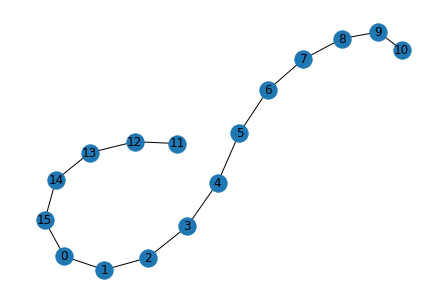

In [20]:
time_begin = time.time()
###############################################################################
# PAIRS DETERMINATION
###############################################################################
# READ data from rough alignment phase 1 and get a thin slice
#data_dir = Path(f'D:/REGISTRATION DATA/External/{field}')
with open(os.path.join(data_dir, 'globalization_axis_phase_1.pkl'), 'rb') as f:
    bundle = pickle.load(f)
edgelist = bundle.determine_pairing_sequence(visual=True, ignore_station_ids=[])

###############################################################################
# ICP
###############################################################################
work_dir = data_dir / 'target_tank' / 'global' / 'ground'
with open(os.path.join(data_dir, 'globalization_axis_phase_1.pkl'), 'rb') as f:
    bundle = pickle.load(f)
# registration
bundle.register_complete()
# write test data
inliner_pcd_combined_down = combine_point_cloud(
    deepcopy(bundle.registration['pcds_down']), bundle.registration['pose_graph'])
write_array2txt(
    os.path.join(work_dir, f'inliers_combined_with_ids_down.txt'),
    inliner_pcd_combined_down
)
# write a slice
l = 3.0
thickness = 0.01
ind = (l <= inliner_pcd_combined_down[:,2]) & (inliner_pcd_combined_down[:,2] <= l + thickness)
write_array2txt(
    os.path.join(work_dir, f'slice_3_down_optimize_.txt'),
    inliner_pcd_combined_down[ind,:]
)

time_end = time.time()
time_total = time_end - time_begin
print(time_total)

In [22]:
bundle.registration.keys()


dict_keys(['pcds_down', 'pcds_full', 'pose_graph'])

In [23]:
# write test data
inliner_pcd_combined_full = combine_point_cloud(
    deepcopy(bundle.registration['pcds_full']), 
    bundle.registration['pose_graph'],
    skip_ind=[10]
)
write_array2txt(
    os.path.join(work_dir, f'combined_with_ids_full.txt'),
    inliner_pcd_combined_full
)

In [33]:
from registration.utils import align_global

In [ ]:
inlier

In [35]:
station_names = [s.name for s in bundle.stations]
align_global(
    bundle.registration['pcds_full'],
    bundle.registration['pose_graph'],
    station_names,
    work_dir / 'final_align',
    [10],
    False
)

In [32]:
fmt = '{:.8f}'
for i, node in enumerate(bundle.registration['pose_graph'].nodes):
    print(f'node {i}')
    t = node.pose
    for row in t:
        for col in row:
            print(fmt.format(col), end=' ')
        print('')

node 0
1.00000000 0.00000000 0.00000000 0.00000000 
0.00000000 1.00000000 0.00000000 -0.00000000 
0.00000000 0.00000000 1.00000000 0.00000000 
0.00000000 0.00000000 0.00000000 1.00000000 
node 1
0.99999999 0.00002777 0.00014164 0.01174050 
-0.00002769 0.99999987 -0.00051792 -0.00940700 
-0.00014166 0.00051792 0.99999986 -0.00483149 
0.00000000 0.00000000 0.00000000 1.00000000 
node 2
0.99999995 0.00011051 0.00030719 0.15099843 
-0.00011034 0.99999985 -0.00054424 -0.16152621 
-0.00030725 0.00054421 0.99999980 -0.01791231 
0.00000000 0.00000000 0.00000000 1.00000000 
node 3
0.99999992 -0.00014802 0.00037030 0.41425387 
0.00014817 0.99999991 -0.00040423 -0.33029941 
-0.00037024 0.00040429 0.99999985 -0.01980217 
0.00000000 0.00000000 0.00000000 1.00000000 
node 4
0.99999999 -0.00014164 0.00003349 0.43217433 
0.00014165 0.99999995 -0.00029949 -0.33303278 
-0.00003344 0.00029949 0.99999995 0.10764022 
0.00000000 0.00000000 0.00000000 1.00000000 
node 5
0.99999999 -0.00004159 0.00009278 0.16